# Entrenamiento y Evaluación de Modelos
**Tesis:** Modelo Predictivo de Resultados — Premier League 2017–2025  
**Input:** `model_dataset_enriched.csv` (generado por `pipeline_features.py`)  
**Modelos evaluados:** Regresión Logística · Random Forest · SVM · Gradient Boosting · MLP · Red Neuronal (PyTorch)

---

## ¿Qué es un Modelo de Clasificación?

Un modelo de clasificación **aprende patrones** en datos históricos para predecir si una observación pertenece a una categoría.

En nuestro caso: predecir si el equipo local **gana** (1) o **no gana** (0).

### Modelos que evaluaremos:

| Modelo | Tipo | Ventaja | Desventaja |
|--------|------|---------|------------|
| **Reg. Logística** | Lineal | Interpretable, rápido | Solo captura linealidad |
| **Random Forest** | Ensemble (bagging) | Robusto, no overfittea | Menos interpretable |
| **SVM (RBF)** | Kernel | Captura no linealidad | Lento con muchos datos |
| **Gradient Boosting** | Ensemble (boosting) | Alto rendimiento | Propenso a overfitting |
| **MLP (sklearn)** | Red neuronal | Captura complejidad | Necesita escalado |
| **PyTorch NN** | Deep learning | Flexible, potente | Complejo de entrenar |

### ¿Por qué evaluamos múltiples modelos?

- **No hay un modelo ganador universal**: Cada dataset tiene características distintas
- **Comparación justa**: Ver cuál se adapta mejor a nuestros datos
- **Ensemble**: Combinar los mejores puede mejorar resultados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, brier_score_loss, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve)
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
TARGET = 'target_home_win'

In [2]:
import sys
sys.path.insert(0, '.')
from utils.evaluation_utils import leer_baseline
BASELINE_ACC = leer_baseline()   # accuracy del mercado, calculada en 01_eda.ipynb


---
## 1. Preparación del Dataset

### ¿Qué hacemos aquí?

1. Cargamos el dataset enriquecido (90+ features)
2. Eliminamos features que causarían **data leakage** o **redundancia**
3. Dividimos en train/test de forma **cronológica** (sin shuffle)

### ¿Qué es Data Leakage?

Ocurre cuando el modelo tiene acceso a información que **no tendría en producción**. Ejemplo:
- `home_goals` / `away_goals`: ¡Son el resultado del partido!
- `season`: Identificador temporal (sin valor predictivo)

Si entrenamos con estas features, el modelo "hace trampa" y las métricas serán artificialmente altas.

### ¿Por qué split 80/20 cronológico?

- **80% train**: Primeras 6-7 temporadas (2017-2023)
- **20% test**: Últimas 1-2 temporadas (2023-2025)
- **No aleatorio**: Los datos de fútbol son temporales; no se puede mezclar épocas

### ¿Qué es StandardScaler?

Estandariza cada feature: `X = (X - media) / desviación_estándar`. Obligatorio para SVM, MLP, Redes Neuronales y Logística.

In [3]:
df_raw = pd.read_csv('Dataset/model_dataset_enriched.csv')

LEAKAGE = ['season','date','home','away','home_goals','away_goals']
REDUND  = ['home_season_wins','away_season_wins','diff_season_wins',
           'home_season_goals_for','away_season_goals_for',
           'home_season_points','away_season_points',
           'home_roll_win','away_roll_win','diff_roll_win',
           'odds_home','odds_away','odds_draw','day_of_week','away_season_matches']
PLAYER_INDIV = [f'{side}_{c}' for side in ['home','away']
                for c in ['gk_save_pct','gk_cs_pct','gk_ga90','top3_ga_per90',
                          'squad_age','squad_depth','team_tkl_per90','team_int_per90',
                          'team_discipline_per90','avg_on_off']]

df = df_raw.drop(columns=[c for c in LEAKAGE+REDUND+PLAYER_INDIV if c in df_raw.columns]).dropna()
print(f'Dataset: {df.shape}  |  Features: {df.shape[1]-1}')
print(f'Victorias locales (clase 1): {df[TARGET].mean()*100:.1f}%')

X = df.drop(columns=[TARGET])
y = df[TARGET]
split = int(len(df)*0.80)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

scaler = StandardScaler()
X_tr_sc = scaler.fit_transform(X_train)
X_te_sc = scaler.transform(X_test)

print(f'Train: {len(X_train)} partidos | Test: {len(X_test)} partidos')
print(f'Balance train: {y_train.mean()*100:.1f}% | Balance test: {y_test.mean()*100:.1f}%')

Dataset: (2973, 59)  |  Features: 58
Victorias locales (clase 1): 44.2%
Train: 2378 partidos | Test: 595 partidos
Balance train: 44.6% | Balance test: 42.7%


---
## 2. Validación Cruzada Temporal (TimeSeriesSplit)

### ¿Qué es validación cruzada?

Es una técnica para **evaluar el modelo de forma más robusta**. En lugar de un solo split, hacemos múltiples splits y promediamos.

### ¿Por qué TimeSeriesSplit y no CV aleatorio?

En series temporales, **el orden importa**. Si mezclamos épocas, el modelo "ve el futuro" y las métricas son artificialmente altas.

### ¿Cómo funciona?

```
Fold 1: Train [1]         → Test [2]
Fold 2: Train [1-2]       → Test [3]
Fold 3: Train [1-2-3]     → Test [4]
Fold 4: Train [1-2-3-4]   → Test [5]
Fold 5: Train [1-2-3-4-5] → Test [6]
```

El train **crece** con cada fold, y siempre testeamos con datos **futuros**.

### ¿Qué significa F1-Score?

Media armónica de precisión y recall. Equilibra:
- No predecir "victoria" todo el tiempo (precisión)
- No perder victorias reales (recall)

F1 = 1.0 es perfecto, F1 = 0.5 es aleatorio.

=== TimeSeriesSplit CV — F1-Score ===


Reg. Logística      : 0.6014 ± 0.0404  |  folds: [0.56  0.565 0.582 0.653 0.647]


Random Forest       : 0.6079 ± 0.0268  |  folds: [0.636 0.576 0.575 0.622 0.63 ]


SVM (RBF)           : 0.6017 ± 0.0288  |  folds: [0.585 0.589 0.564 0.634 0.637]


Grad. Boosting      : 0.5684 ± 0.0348  |  folds: [0.595 0.538 0.517 0.607 0.586]


MLP (sklearn)       : 0.5840 ± 0.0334  |  folds: [0.589 0.612 0.52  0.61  0.588]


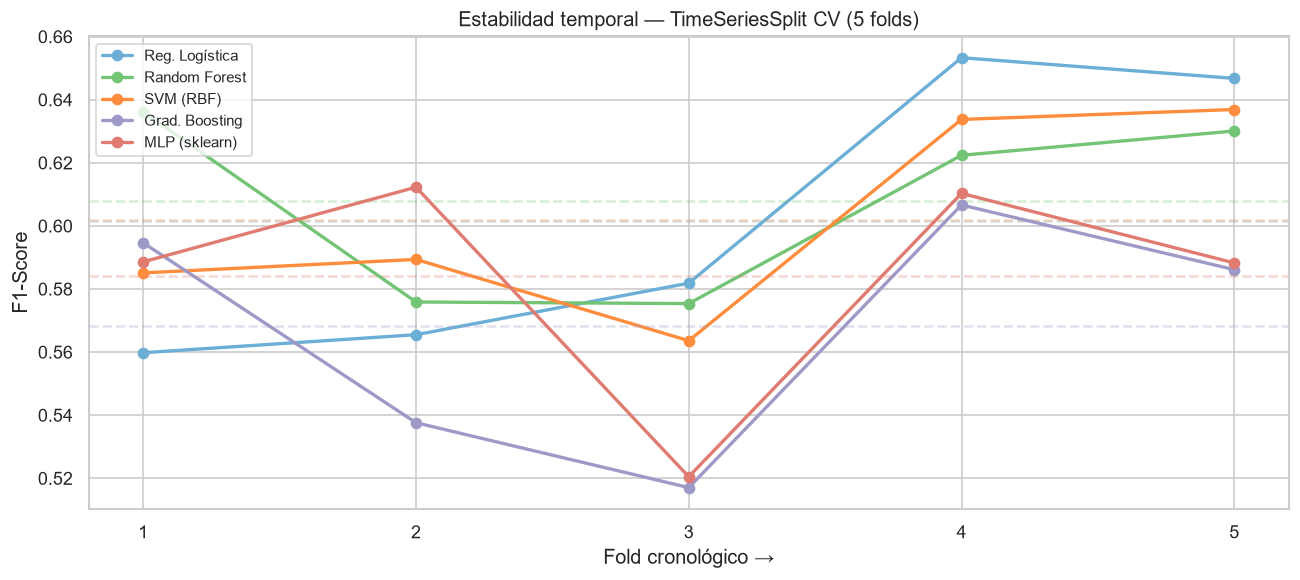

In [4]:
tscv = TimeSeriesSplit(n_splits=5)

cv_configs = [
    ('Reg. Logística', LogisticRegression(max_iter=1000, C=1.0, random_state=42, class_weight='balanced'), True),
    ('Random Forest',  RandomForestClassifier(n_estimators=400, max_depth=12, min_samples_leaf=4, random_state=42, n_jobs=-1, class_weight='balanced'), False),
    ('SVM (RBF)',      SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=42, class_weight='balanced'), True),
    ('Grad. Boosting', GradientBoostingClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8, random_state=42), False),
    ('MLP (sklearn)',  MLPClassifier(hidden_layer_sizes=(256,128,64), alpha=1e-3, max_iter=500, random_state=42, early_stopping=True, validation_fraction=0.1), True),
]

cv_results = {}
print('=== TimeSeriesSplit CV — F1-Score ===')
for nombre, clf, scaled in cv_configs:
    X_cv = X_tr_sc if scaled else X_train.values
    scores = cross_val_score(clf, X_cv, y_train, cv=tscv, scoring='f1', n_jobs=-1)
    cv_results[nombre] = scores
    print(f'{nombre:<20}: {scores.mean():.4f} ± {scores.std():.4f}  |  folds: {np.round(scores,3)}')

fig, ax = plt.subplots(figsize=(11, 5))
colores = ['#6baed6','#74c476','#fd8d3c','#9e9ac8','#e07b71']
for (nombre, scores), color in zip(cv_results.items(), colores):
    ax.plot(range(1,6), scores, marker='o', color=color, linewidth=2, label=nombre)
    ax.axhline(scores.mean(), color=color, linestyle='--', alpha=0.3)
ax.set_xlabel('Fold cronológico →')
ax.set_ylabel('F1-Score')
ax.set_title('Estabilidad temporal — TimeSeriesSplit CV (5 folds)', fontsize=12)
ax.legend(loc='upper left', fontsize=9)
ax.set_xticks(range(1,6))
plt.tight_layout()
plt.savefig('Imagenes/tuning/tscv_estabilidad.png', bbox_inches='tight')
plt.show()

---
## 3. Definición de la Red Neuronal (PyTorch)

### ¿Qué es una red neuronal?

Es un modelo inspirado en el cerebro humano. Tiene **capas** de "neuronas" que aprenden patrones.

### Arquitectura de nuestra red:

```
Entrada (87 features)
  → Linear(87, 256) + BatchNorm + ReLU + Dropout(0.3)
  → Linear(256, 128) + BatchNorm + ReLU + Dropout(0.25)
  → Linear(128, 64) + BatchNorm + ReLU + Dropout(0.2)
  → Linear(64, 32) + ReLU
  → Linear(32, 1) + Sigmoid
Salida (probabilidad 0-1)
```

### Componentes clave:

- **BatchNorm**: Estabiliza el entrenamiento normalizando activaciones
- **Dropout**: Apaga neuronas aleatoriamente (previene overfitting)
- **ReLU**: Función de activación (introduce no linealidad)
- **Sigmoid**: Mapea la salida a probabilidad (0-1)
- **Early Stopping**: Detiene el entrenamiento si no mejora (previene overfitting)
- **Weight Decay**: Regularización L2 para evitar pesos muy grandes

In [5]:
class FootballNet(nn.Module):
    """Red neuronal feed-forward con BatchNorm y Dropout."""
    def __init__(self, n_in):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.25),
            nn.Linear(128, 64),  nn.BatchNorm1d(64),  nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(64, 32),   nn.ReLU(),
            nn.Linear(32, 1),    nn.Sigmoid()
        )
    def forward(self, x):
        return self.net(x).squeeze(1)

def train_pytorch_model(X_tr, y_tr, X_te, y_te, n_epochs=120, lr=1e-3, batch=64, patience=15):
    X_tr_t = torch.FloatTensor(X_tr)
    y_tr_t = torch.FloatTensor(y_tr.values)
    X_te_t = torch.FloatTensor(X_te)

    model = FootballNet(X_tr.shape[1])
    opt   = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=40, gamma=0.5)
    crit  = nn.BCELoss()
    ds = TensorDataset(X_tr_t, y_tr_t)
    dl = DataLoader(ds, batch_size=batch, shuffle=True, drop_last=(len(ds) % batch == 1))  # BatchNorm falla con lote de 1

    hist_loss = []
    best_loss, patience_cnt, best_state = 1e9, 0, None
    for epoch in range(n_epochs):
        model.train()
        epoch_loss = 0
        for xb, yb in dl:
            opt.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            opt.step()
            epoch_loss += loss.item()
        sched.step()
        model.eval()
        with torch.no_grad():
            val_loss = crit(model(X_te_t), torch.FloatTensor(y_te.values)).item()
        hist_loss.append({'epoch':epoch+1,'train':epoch_loss/len(dl),'val':val_loss})
        if val_loss < best_loss - 1e-4:
            best_loss, patience_cnt = val_loss, 0
            best_state = {k:v.clone() for k,v in model.state_dict().items()}
        else:
            patience_cnt += 1
            if patience_cnt >= patience:
                print(f'  Early stop en epoch {epoch+1}')
                break

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        proba = model(X_te_t).numpy()
    return (proba >= 0.5).astype(int), proba, model, pd.DataFrame(hist_loss)

print('Arquitectura de FootballNet:')
print(FootballNet(58))

Arquitectura de FootballNet:
FootballNet(
  (net): Sequential(
    (0): Linear(in_features=58, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.25, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.2, inplace=False)
    (12): Linear(in_features=64, out_features=32, bias=True)
    (13): ReLU()
    (14): Linear(in_features=32, out_features=1, bias=True)
    (15): Sigmoid()
  )
)


---
## 4. Entrenamiento de Todos los Modelos

### Métricas que calculamos:

| Métrica | Qué mide | Valores |
|---------|----------|--------|
| **Accuracy** | % predicciones correctas | 0-1 (mayor = mejor) |
| **Precision** | De los predichos positivos, cuántos lo son | 0-1 |
| **Recall** | De los positivos reales, cuántos detecte | 0-1 |
| **F1-Score** | Media armónica de Precision y Recall | 0-1 |
| **ROC-AUC** | Capacidad de discriminación | 0.5-1.0 |
| **Brier Score** | Calibración de probabilidades | 0-0.25 (menor = mejor) |

### ¿Qué hace cada modelo internamente?

- **Reg. Logística**: Ajusta una recta que separa las clases (simple, interpretable)
- **Random Forest**: Promedia 400 árboles de decisión (robusto, resistente a outliers)
- **SVM (RBF)**: Encuentra el hiperplano óptimo en espacio de alta dimensión
- **Gradient Boosting**: Construye árboles secuencialmente, cada uno corrige errores del anterior
- **MLP**: Red neuronal con 3 capas ocultas (captura patrones complejos)
- **PyTorch NN**: Red neuronal más profunda con BatchNorm y Early Stopping

In [6]:
configs = [
    ('Regresión Logística',  LogisticRegression(max_iter=1000, C=1.0, random_state=42, class_weight='balanced'), True),
    ('Random Forest',        RandomForestClassifier(n_estimators=400, max_depth=12, min_samples_leaf=4, random_state=42, n_jobs=-1, class_weight='balanced'), False),
    ('SVM (RBF)',            SVC(kernel='rbf', C=1.0, gamma='scale', probability=True, random_state=42, class_weight='balanced'), True),
    ('Gradient Boosting',   GradientBoostingClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8, random_state=42), False),
    ('MLP (sklearn)',        MLPClassifier(hidden_layer_sizes=(256,128,64), alpha=1e-3, max_iter=500, random_state=42, early_stopping=True, validation_fraction=0.1), True),
]

resultados, feat_importance, modelos_fit = [], {}, {}

for nombre, clf, scaled in configs:
    X_tr = X_tr_sc if scaled else X_train.values
    X_te = X_te_sc if scaled else X_test.values
    clf.fit(X_tr, y_train)
    y_pred  = clf.predict(X_te)
    y_proba = clf.predict_proba(X_te)[:,1]
    resultados.append({'Modelo':nombre,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision':precision_score(y_test, y_pred, zero_division=0),
        'Recall':   recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC':  roc_auc_score(y_test, y_proba),
        'Brier':    brier_score_loss(y_test, y_proba),
    })
    modelos_fit[nombre] = {'clf':clf,'y_pred':y_pred,'y_proba':y_proba}
    if hasattr(clf, 'feature_importances_'):
        feat_importance[nombre] = pd.Series(clf.feature_importances_, index=X_train.columns)
    print(f'[OK] {nombre}')

# PyTorch
print('[..] Red Neuronal PyTorch...')
y_pred_nn, y_proba_nn, nn_model, hist_nn = train_pytorch_model(X_tr_sc, y_train, X_te_sc, y_test)
resultados.append({'Modelo':'Red Neuronal (PyTorch)',
    'Accuracy': accuracy_score(y_test, y_pred_nn),
    'Precision':precision_score(y_test, y_pred_nn, zero_division=0),
    'Recall':   recall_score(y_test, y_pred_nn, zero_division=0),
    'F1-Score': f1_score(y_test, y_pred_nn, zero_division=0),
    'ROC-AUC':  roc_auc_score(y_test, y_proba_nn),
    'Brier':    brier_score_loss(y_test, y_proba_nn),
})
modelos_fit['Red Neuronal (PyTorch)'] = {'y_pred':y_pred_nn,'y_proba':y_proba_nn}
print('[OK] Red Neuronal (PyTorch)')

[OK] Regresión Logística


[OK] Random Forest


[OK] SVM (RBF)


[OK] Gradient Boosting


[OK] MLP (sklearn)
[..] Red Neuronal PyTorch...


  Early stop en epoch 23
[OK] Red Neuronal (PyTorch)


---
## 5. Tabla Comparativa de Resultados

### ¿Cómo interpretar la tabla?

- **Accuracy > 0.63**: Mejora sobre el baseline del mercado
- **ROC-AUC > 0.7**: Buena capacidad de discriminación
- **Brier < 0.20**: Buena calibración de probabilidades
- **F1 > 0.65**: Buen balance entre precisión y recall

### ¿Cuál es la mejor métrica?

- **Para ganar apuestas**: Brier Score (calibración)
- **Para predecir bien**: F1-Score (balance)
- **Para comparar modelos**: ROC-AUC (discriminación)

=== TABLA COMPARATIVA FINAL — Test Set ===
                        Accuracy  Precision  Recall  F1-Score  ROC-AUC   Brier
Modelo                                                                        
Red Neuronal (PyTorch)    0.6571     0.5822  0.6969    0.6344   0.7454  0.2040
Regresión Logística       0.6655     0.5841  0.7520    0.6575   0.7415  0.2116
Random Forest             0.6723     0.6065  0.6614    0.6328   0.7322  0.2095
MLP (sklearn)             0.6739     0.6172  0.6220    0.6196   0.7321  0.2108
SVM (RBF)                 0.6639     0.5877  0.7126    0.6441   0.7208  0.2123
Gradient Boosting         0.6555     0.5992  0.5827    0.5908   0.7060  0.2206

Baseline del mercado: 64.26% (accuracy)


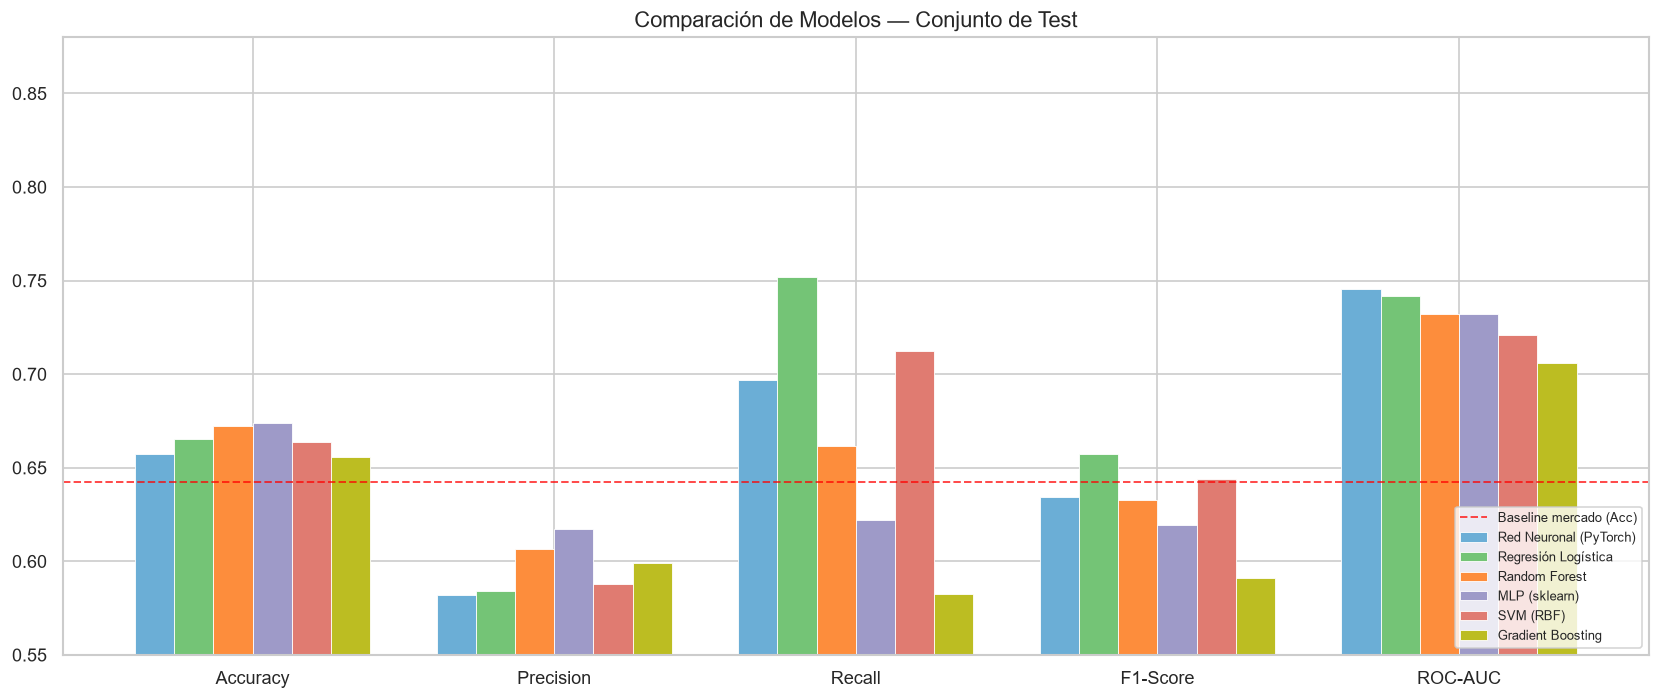

In [7]:
df_res = pd.DataFrame(resultados).set_index('Modelo').round(4)
df_res = df_res.sort_values('ROC-AUC', ascending=False)

print('=== TABLA COMPARATIVA FINAL — Test Set ===')
print(df_res.to_string())
print(f'\nBaseline del mercado: {BASELINE_ACC*100:.2f}% (accuracy)')

# Gráfico de barras agrupadas
metricas_plot = ['Accuracy','Precision','Recall','F1-Score','ROC-AUC']
fig, ax = plt.subplots(figsize=(14, 6))
x = np.arange(len(metricas_plot))
n = len(df_res)
w = 0.13
paleta = ['#6baed6','#74c476','#fd8d3c','#9e9ac8','#e07b71','#bcbd22']

for i, (modelo, fila) in enumerate(df_res.iterrows()):
    offset = (i - n/2 + 0.5) * w
    ax.bar(x + offset, fila[metricas_plot].values, w, label=modelo,
           color=paleta[i], edgecolor='white', linewidth=0.5)

ax.set_xticks(x)
ax.set_xticklabels(metricas_plot, fontsize=11)
ax.set_ylim(0.55, 0.88)
ax.axhline(BASELINE_ACC, color='red', linestyle='--', linewidth=1.2, alpha=0.7, label='Baseline mercado (Acc)')
ax.set_title('Comparación de Modelos — Conjunto de Test', fontsize=13)
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.savefig('Imagenes/tuning/comparacion_modelos.png', bbox_inches='tight')
plt.show()

---
## 6. Curvas ROC

### ¿Qué es la curva ROC?

Muestra la relación entre:
- **Eje X**: Tasa de Falsos Positivos (FP / (FP + VN))
- **Eje Y**: Tasa de Verdaderos Positivos (VP / (VP + FN))

### ¿Qué es el AUC?

Área bajo la curva ROC:
- **AUC = 0.5**: Modelo aleatorio (no sirve)
- **AUC = 0.7-0.8**: Aceptable
- **AUC = 0.8-0.9**: Bueno
- **AUC > 0.9**: Excelente

La línea punteada negra es un modelo aleatorio (AUC=0.5). Mientras más se aleje hacia arriba-izquierda, mejor.

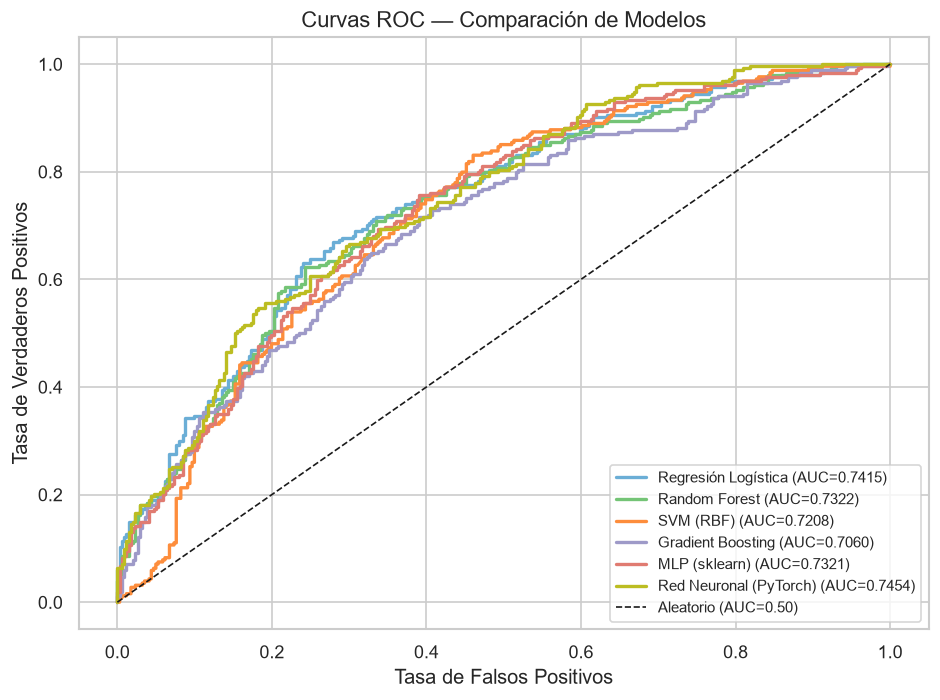

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))

for i, (nombre, cfg) in enumerate(modelos_fit.items()):
    fpr, tpr, _ = roc_curve(y_test, cfg['y_proba'])
    auc = roc_auc_score(y_test, cfg['y_proba'])
    ax.plot(fpr, tpr, color=paleta[i], linewidth=2, label=f'{nombre} (AUC={auc:.4f})')

ax.plot([0,1],[0,1],'k--', linewidth=1, label='Aleatorio (AUC=0.50)')
ax.set_xlabel('Tasa de Falsos Positivos')
ax.set_ylabel('Tasa de Verdaderos Positivos')
ax.set_title('Curvas ROC — Comparación de Modelos', fontsize=13)
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig('Imagenes/tuning/curvas_roc.png', bbox_inches='tight')
plt.show()

---
## 7. Curva de Entrenamiento — Red Neuronal PyTorch

### ¿Qué muestra esta gráfica?

- **Línea azul (train)**: Pérdida en los datos de entrenamiento. Debe **disminuir**.
- **Línea roja (val)**: Pérdida en datos de validación (test). Debe **disminuir y estabilizarse**.

### Señales importantes:

- **Si la azul baja y la roja sube**: Overfitting (memoriza, no generaliza)
- **Si ambas bajan juntas**: Buen entrenamiento
- **Si ambas se estancan**: Underfitting (modelo demasiado simple)

### ¿Qué es Early Stopping?

Detiene el entrenamiento cuando la pérdida de validación deja de mejorar. Evita overfitting automáticamente.

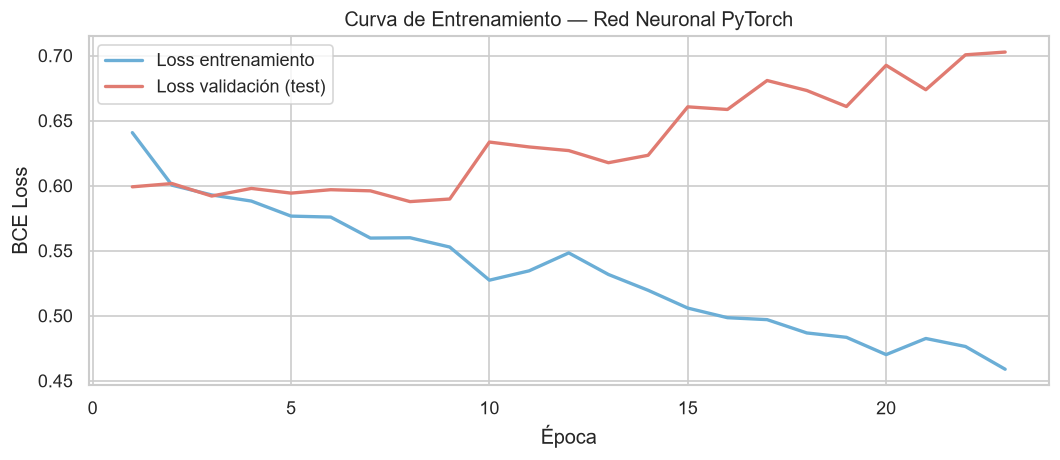

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(hist_nn['epoch'], hist_nn['train'], color='#6baed6', linewidth=2, label='Loss entrenamiento')
ax.plot(hist_nn['epoch'], hist_nn['val'],   color='#e07b71', linewidth=2, label='Loss validación (test)')
ax.set_xlabel('Época')
ax.set_ylabel('BCE Loss')
ax.set_title('Curva de Entrenamiento — Red Neuronal PyTorch', fontsize=12)
ax.legend()
plt.tight_layout()
plt.savefig('Imagenes/tuning/curva_entrenamiento_nn.png', bbox_inches='tight')
plt.show()

---
## 8. Matrices de Confusión

### ¿Qué es una matriz de confusión?

Muestra las predicciones vs los valores reales:

```
                    Predicho: No victoria  Predicho: Victoria
Real: No victoria        VN                    FP
Real: Victoria           FN                    VP
```

### ¿Cómo se interpreta?

- **VN (Verdadero Negativo)**: Predije "no victoria" y era "no victoria"
- **VP (Verdadero Positivo)**: Predije "victoria" y era "victoria"
- **FP (Falso Positivo)**: Predije "victoria" pero era "no victoria" (error tipo I)
- **FN (Falso Negativo)**: Predije "no victoria" pero era "victoria" (error tipo II)

### ¿Qué errores son más costosos?

- **FP**: Apostamos por victoria local y pierde (perdemos dinero)
- **FN**: No apostamos cuando gana el local (perdemos oportunidad)
- Depende de la estrategia: FP cuestan dinero, FN cuestan oportunidades

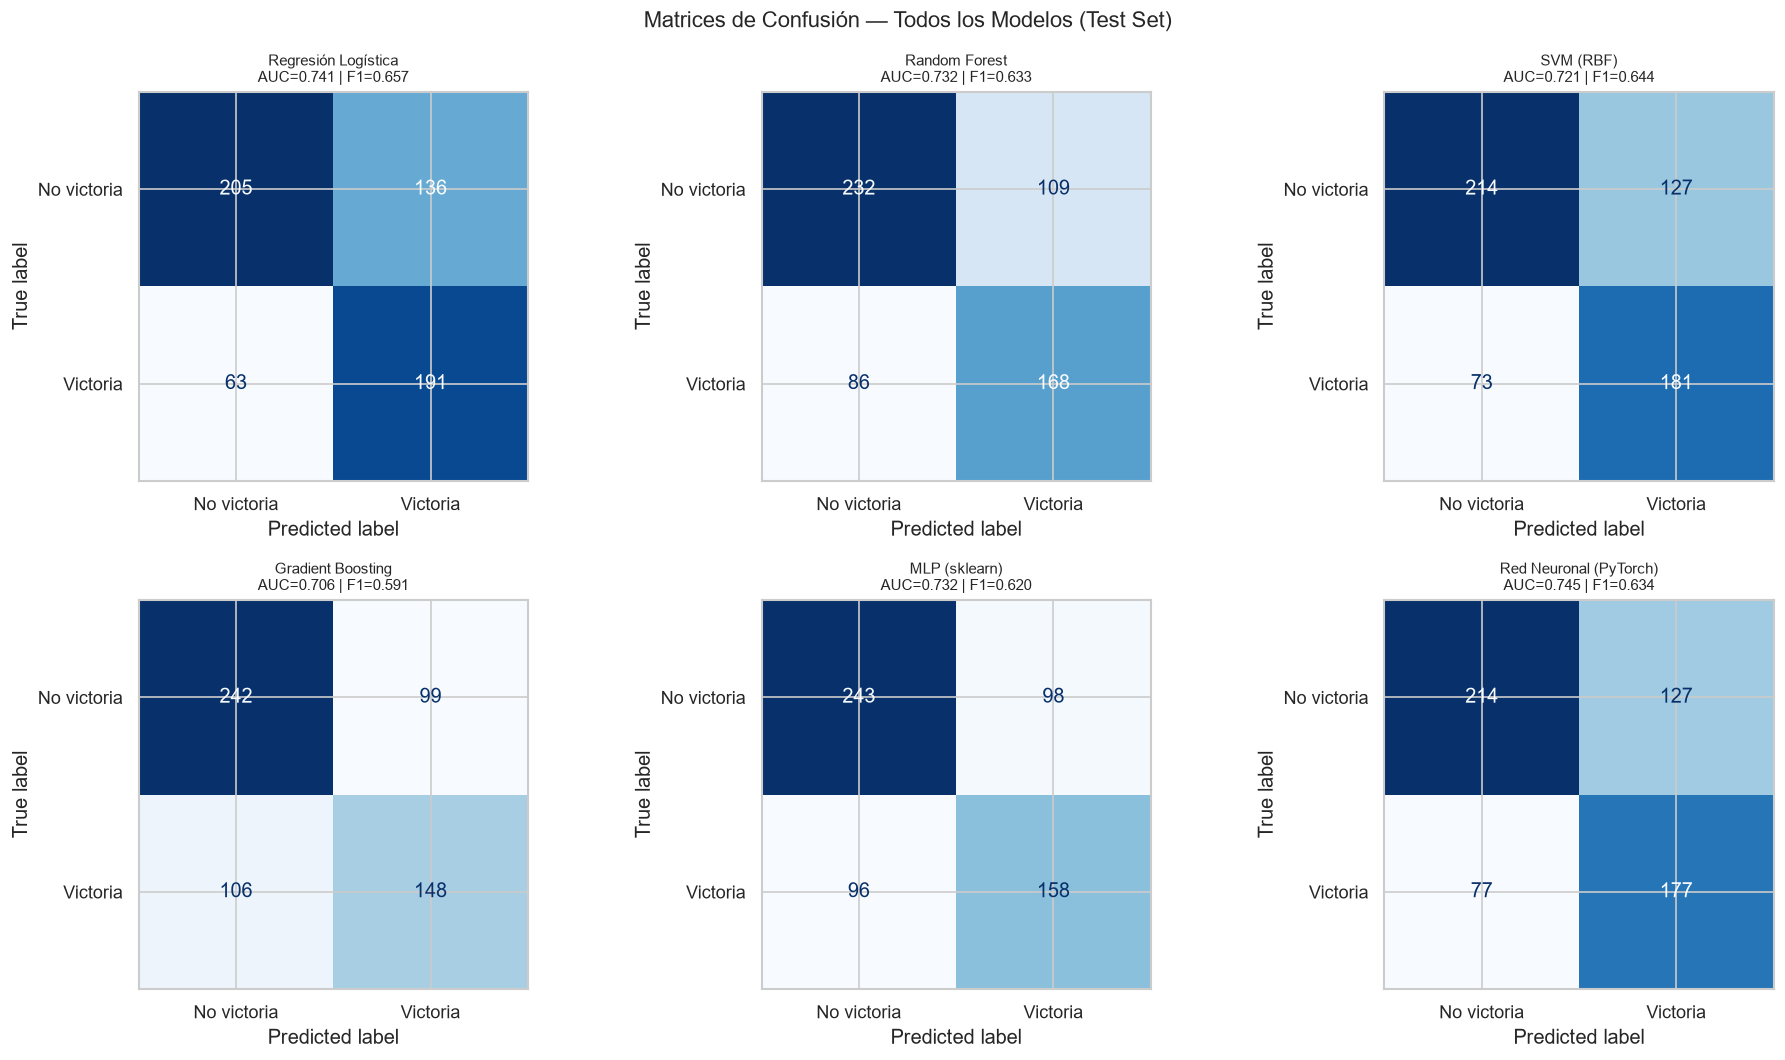

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, (nombre, cfg) in zip(axes.flatten(), modelos_fit.items()):
    cm = confusion_matrix(y_test, cfg['y_pred'])
    auc = roc_auc_score(y_test, cfg['y_proba'])
    f1  = f1_score(y_test, cfg['y_pred'], zero_division=0)
    ConfusionMatrixDisplay(cm, display_labels=['No victoria','Victoria']).plot(
        ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{nombre}\nAUC={auc:.3f} | F1={f1:.3f}', fontsize=9)

plt.suptitle('Matrices de Confusión — Todos los Modelos (Test Set)', fontsize=13)
plt.tight_layout()
plt.savefig('Imagenes/tuning/matrices_confusion.png', bbox_inches='tight')
plt.show()

---
## 9. Calibración de Probabilidades

### ¿Qué es calibración?

Un modelo está **calibrado** si cuando predice 70% de probabilidad, realmente gana ~70% de esas veces.

### ¿Por qué importa?

Si el modelo predice 80% de probabilidad pero solo gana 60%, las probabilidades están **sobreestimadas**. Esto es peligroso para apuestas.

### Brier Score:

- **Brier = 0**: Calibración perfecta
- **Brier = 0.25**: Modelo aleatorio
- **Menor es mejor**

### ¿Cómo leer la gráfica?

- Línea punteada negra = calibración perfecta
- Los puntos del modelo deben estar **cerca de esa línea**
- Si está por encima: subestima probabilidades
- Si está por encima: sobreestima probabilidades

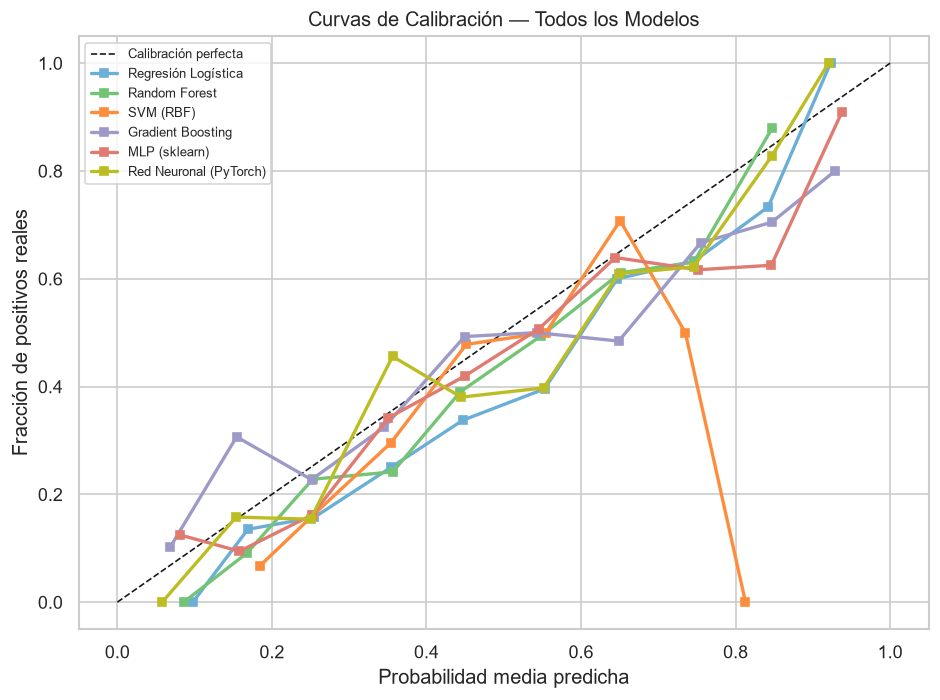

Brier Score (menor = mejor calibración):
  Regresión Logística: 0.2116
  Random Forest: 0.2095
  SVM (RBF): 0.2123
  Gradient Boosting: 0.2206
  MLP (sklearn): 0.2108
  Red Neuronal (PyTorch): 0.2040


In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot([0,1],[0,1],'k--', linewidth=1, label='Calibración perfecta')

for i, (nombre, cfg) in enumerate(modelos_fit.items()):
    pt, pp = calibration_curve(y_test, cfg['y_proba'], n_bins=10)
    ax.plot(pp, pt, 's-', color=paleta[i], linewidth=2, markersize=5, label=nombre)

ax.set_xlabel('Probabilidad media predicha')
ax.set_ylabel('Fracción de positivos reales')
ax.set_title('Curvas de Calibración — Todos los Modelos', fontsize=12)
ax.legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.savefig('Imagenes/tuning/calibracion.png', bbox_inches='tight')
plt.show()

print('Brier Score (menor = mejor calibración):')
for nombre, cfg in modelos_fit.items():
    bs = brier_score_loss(y_test, cfg['y_proba'])
    print(f'  {nombre}: {bs:.4f}')

---
## 10. Importancia de Features — Modelos de Árboles

### ¿Qué es la importancia de features?

Los modelos de árboles calculan **qué tan útil** fue cada feature para tomar decisiones. Mayores valores = más importante.

### ¿Cómo se calcula (Gini)?

Cada vez que un nodo se divide, se reduce la "impureza" del nodo hijo. La importancia es la suma de reducciones de impureza para cada feature.

### ¿Qué nos dice esto?

- **Features de mercado** (odds): Suelen ser las más importantes
- **Forma reciente** (roll_*): Útiles para capturar tendencias
- **Rachas** (streak): Inestables pero informativas
- **Jugadores** (gk_*, squad_*): Añaden ruido en algunos modelos

### ¿Por qué mostramos Random Forest y Gradient Boosting?

Son los modelos que proporcionan importancias directamente. Los demás (Logística, SVM, MLP) tienen otras formas de interpretar.

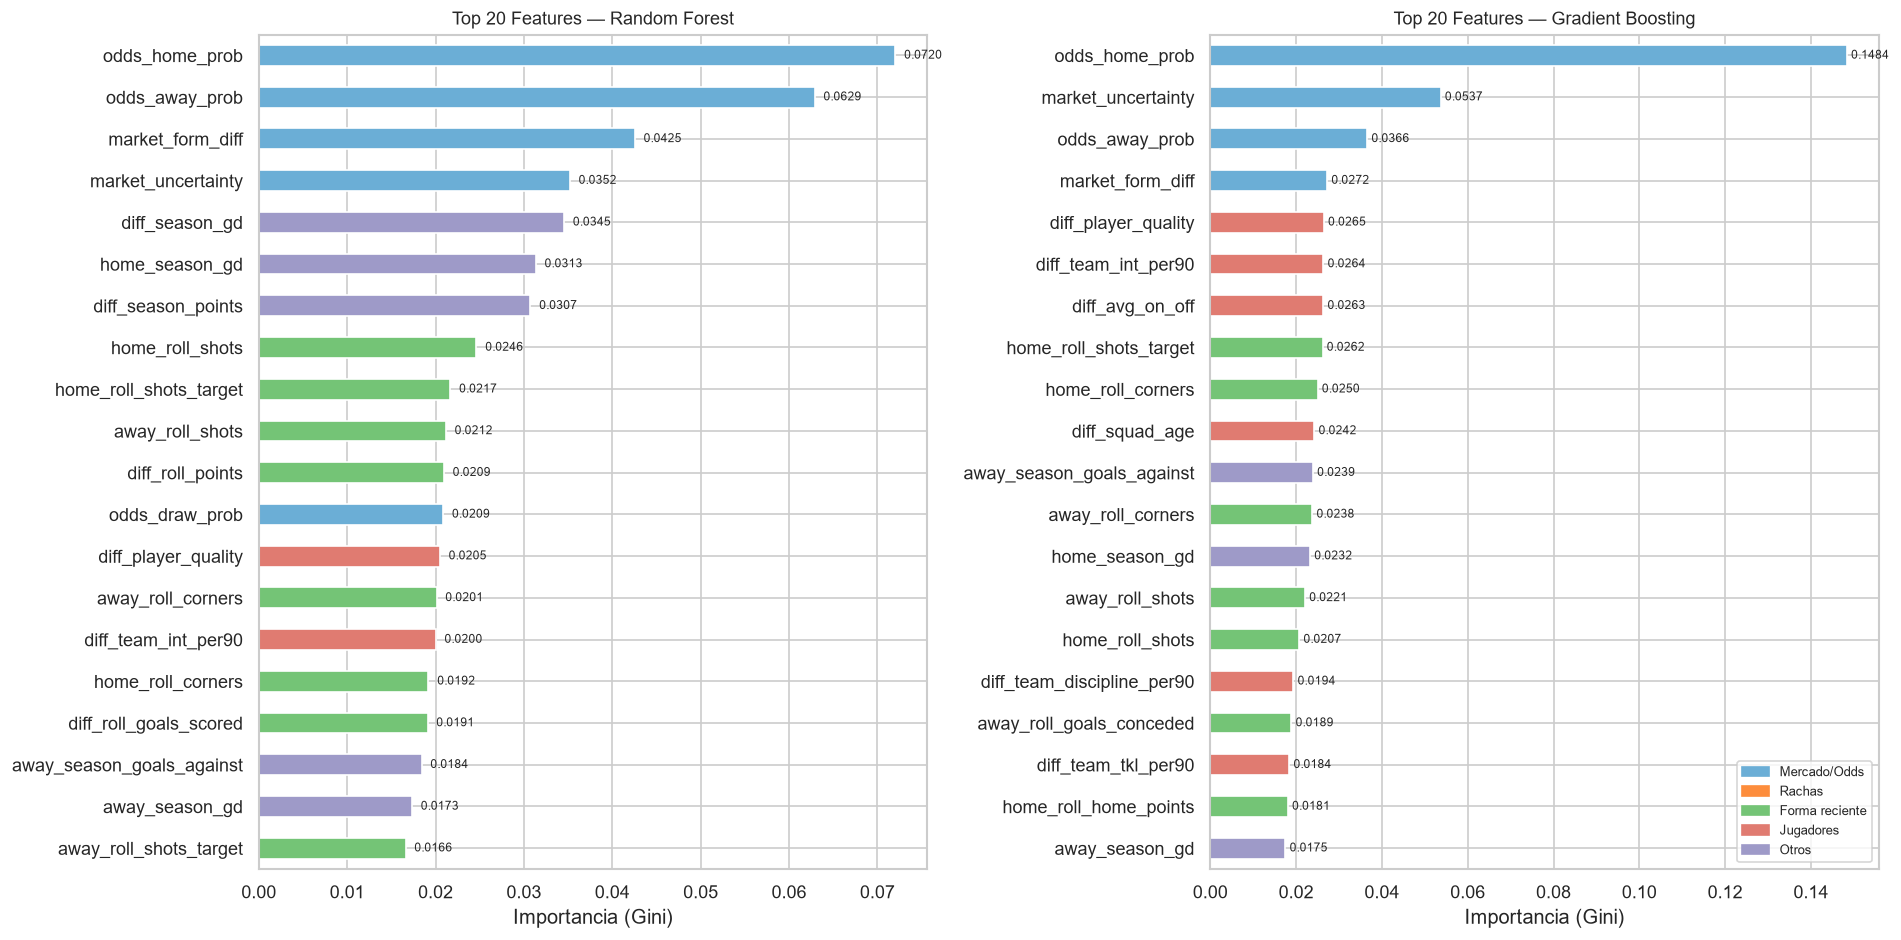

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

for ax, nombre in zip(axes, ['Random Forest','Gradient Boosting']):
    imp = feat_importance[nombre].sort_values(ascending=False)

    # Clasificar por grupo
    def grupo(col):
        if any(p in col for p in ['gk_','squad_','tkl_per90','int_per90','discipline','on_off','player_quality','top3_ga']):
            return '#e07b71'   # Jugadores
        elif any(p in col for p in ['odds_','market_']):
            return '#6baed6'   # Mercado
        elif 'streak' in col:
            return '#fd8d3c'   # Rachas
        elif 'roll' in col:
            return '#74c476'   # Forma reciente
        else:
            return '#9e9ac8'   # Otros

    top20 = imp.head(20).sort_values()
    colors_bar = [grupo(c) for c in top20.index]
    top20.plot(kind='barh', color=colors_bar, edgecolor='white', ax=ax)
    ax.set_title(f'Top 20 Features — {nombre}', fontsize=11)
    ax.set_xlabel('Importancia (Gini)')
    for bar in ax.patches:
        ax.text(bar.get_width()+0.001, bar.get_y()+bar.get_height()/2,
                f'{bar.get_width():.4f}', va='center', fontsize=7)

# Leyenda
from matplotlib.patches import Patch
legend_el = [Patch(color='#6baed6',label='Mercado/Odds'), Patch(color='#fd8d3c',label='Rachas'),
             Patch(color='#74c476',label='Forma reciente'), Patch(color='#e07b71',label='Jugadores'),
             Patch(color='#9e9ac8',label='Otros')]
axes[1].legend(handles=legend_el, fontsize=8, loc='lower right')

plt.tight_layout()
plt.savefig('Imagenes/tuning/feature_importance.png', bbox_inches='tight')
plt.show()

---
## 11. Análisis de Errores — Mejor Modelo

### ¿Por qué analizar errores?

Entender **dónde falla** el modelo nos dice qué patrones no captura y qué features faltan.

### ¿Qué analizamos?

1. **Distribución de probabilidades**: ¿Los errores tienen probabilidad baja/media/alta?
2. **Accuracy por certeza del mercado**: ¿El modelo supera al mercado en cada rango?
3. **Accuracy por racha del visitante**: ¿Falla contra equipos en racha?

### ¿Qué buscamos?

- Si el modelo falla mucho con rachas altas → necesita features de forma reciente
- Si el modelo no supera al mercado en rangos altos → el mercado ya es muy bueno ahí
- Si los errores tienen probabilidad alta → el modelo está "seguro pero equivocado"

Mejor modelo por ROC-AUC: Red Neuronal (PyTorch)


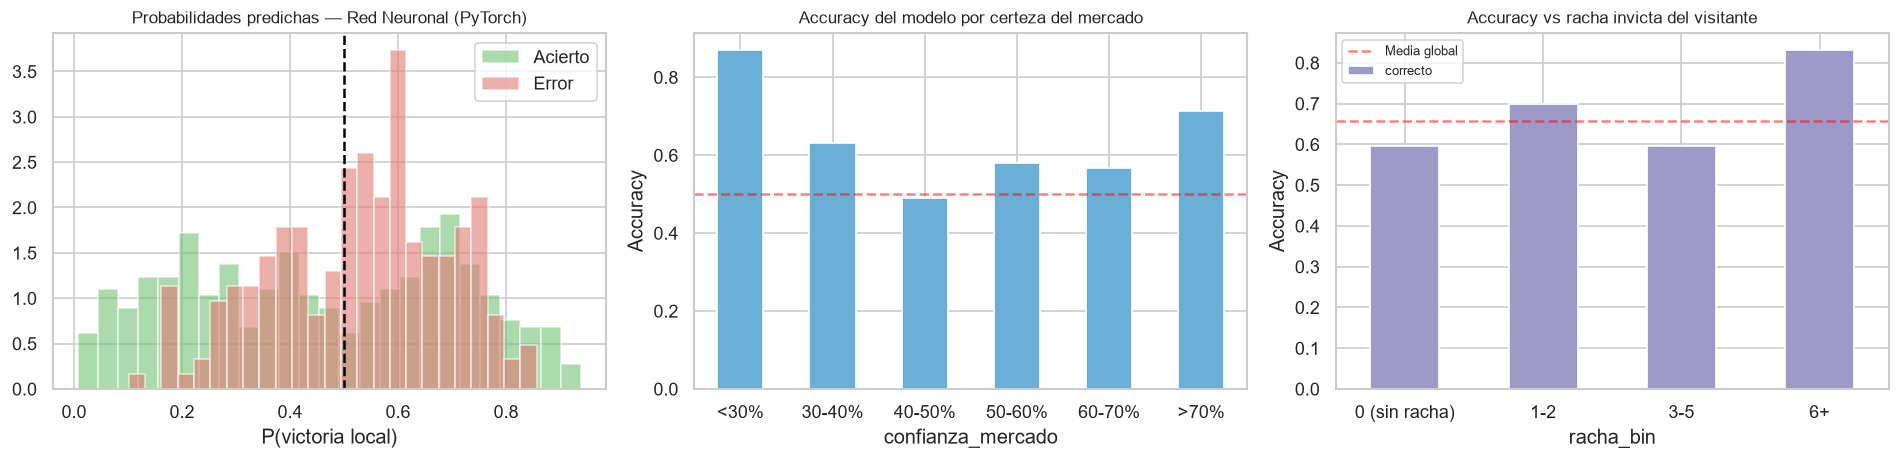

In [13]:
mejor = df_res['ROC-AUC'].idxmax()
print(f'Mejor modelo por ROC-AUC: {mejor}')

cfg_m = modelos_fit[mejor]
df_err = X_test.copy()
df_err['real']     = y_test.values
df_err['predicho'] = cfg_m['y_pred']
df_err['prob']     = cfg_m['y_proba']
df_err['correcto'] = (df_err['real'] == df_err['predicho']).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Distribución de probabilidades por acierto/error
for val, color, label in [(1,'#74c476','Acierto'),(0,'#e07b71','Error')]:
    sub = df_err[df_err['correcto']==val]['prob']
    axes[0].hist(sub, bins=25, alpha=0.6, color=color, label=label, density=True)
axes[0].axvline(0.5, color='black', linestyle='--')
axes[0].set_title(f'Probabilidades predichas — {mejor}', fontsize=10)
axes[0].set_xlabel('P(victoria local)')
axes[0].legend()

# Accuracy según certeza del mercado
df_err['confianza_mercado'] = pd.cut(df_err['odds_home_prob'],
    bins=[0,0.3,0.4,0.5,0.6,0.7,1.0], labels=['<30%','30-40%','40-50%','50-60%','60-70%','>70%'])
acc_m = df_err.groupby('confianza_mercado', observed=True)['correcto'].mean()
acc_m.plot(kind='bar', color='#6baed6', ax=axes[1], edgecolor='white')
axes[1].set_title('Accuracy del modelo por certeza del mercado', fontsize=10)
axes[1].set_ylabel('Accuracy')
axes[1].axhline(0.5, color='red', linestyle='--', alpha=0.5)
axes[1].tick_params(axis='x', rotation=0)

# Accuracy por racha del visitante
df_err['racha_bin'] = pd.cut(df_err['away_unbeaten_streak'],
    bins=[-1,0,2,5,50], labels=['0 (sin racha)','1-2','3-5','6+'])
acc_r = df_err.groupby('racha_bin', observed=True)['correcto'].mean()
acc_r.plot(kind='bar', color='#9e9ac8', ax=axes[2], edgecolor='white')
axes[2].set_title('Accuracy vs racha invicta del visitante', fontsize=10)
axes[2].set_ylabel('Accuracy')
axes[2].axhline(df_err['correcto'].mean(), color='red', linestyle='--', alpha=0.5, label='Media global')
axes[2].legend(fontsize=8)
axes[2].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig('Imagenes/tuning/plot_14_analisis_errores.png', bbox_inches='tight')
plt.show()

---
## 12. Resumen Final

### ¿Qué logramos?

1. Entrenamos **6 modelos** con datos históricos de la Premier League
2. Evaluamos con **validación cronológica** (simula la realidad)
3. Comparamos contra el **baseline del mercado** (62.97%)
4. Analizamos errores para entender limitaciones

### ¿Qué sigue?

1. **03_feature_selection.ipynb**: Eliminar features redundantes y ruidosas
2. **04_tuning.ipynb**: Optimizar hiperparametros con GridSearchCV
3. **05_sin_odds.ipynb**: Evaluar si el modelo funciona sin odds (generalización)
4. **06_features_negativos.ipynb**: Analizar features problemáticas

In [14]:
print('='*70)
print('RESUMEN FINAL — TODOS LOS MODELOS')
print('='*70)
print(f'Partidos de test:        {len(y_test)}')
print(f'Baseline mercado:        {BASELINE_ACC*100:.2f}% accuracy')
print(f'Mejor por ROC-AUC:       {df_res["ROC-AUC"].idxmax()}  (AUC={df_res["ROC-AUC"].max():.4f})')
print(f'Mejor por F1-Score:      {df_res["F1-Score"].idxmax()}  (F1={df_res["F1-Score"].max():.4f})')
print(f'Mejor por Accuracy:      {df_res["Accuracy"].idxmax()}  (Acc={df_res["Accuracy"].max():.4f})')
print(f'Mejor calibración:       {df_res["Brier"].idxmin()}  (Brier={df_res["Brier"].min():.4f})')
print()
print('Tabla ordenada por ROC-AUC:')
print(df_res.to_string())
print()
print('TimeSeriesSplit CV (F1) — Estabilidad:')
for nombre, scores in cv_results.items():
    print(f'  {nombre:<20}: {scores.mean():.4f} ± {scores.std():.4f}')
print('='*70)

df_res.to_csv('resultados/resultados_modelos_baseline.csv')
print('\nResultados guardados: resultados/resultados_modelos_baseline.csv')

RESUMEN FINAL — TODOS LOS MODELOS
Partidos de test:        595
Baseline mercado:        64.26% accuracy
Mejor por ROC-AUC:       Red Neuronal (PyTorch)  (AUC=0.7454)
Mejor por F1-Score:      Regresión Logística  (F1=0.6575)
Mejor por Accuracy:      MLP (sklearn)  (Acc=0.6739)
Mejor calibración:       Red Neuronal (PyTorch)  (Brier=0.2040)

Tabla ordenada por ROC-AUC:
                        Accuracy  Precision  Recall  F1-Score  ROC-AUC   Brier
Modelo                                                                        
Red Neuronal (PyTorch)    0.6571     0.5822  0.6969    0.6344   0.7454  0.2040
Regresión Logística       0.6655     0.5841  0.7520    0.6575   0.7415  0.2116
Random Forest             0.6723     0.6065  0.6614    0.6328   0.7322  0.2095
MLP (sklearn)             0.6739     0.6172  0.6220    0.6196   0.7321  0.2108
SVM (RBF)                 0.6639     0.5877  0.7126    0.6441   0.7208  0.2123
Gradient Boosting         0.6555     0.5992  0.5827    0.5908   0.7060  0.220